# Responding candidates

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from utils import load_responses

REPO_ROOT = Path("..")
RESPONSES_DIR = REPO_ROOT / "data" / "stance_responses"

plt.style.use(REPO_ROOT / "snap.mplstyle")

## Read the response files

In [2]:
df = load_responses(RESPONSES_DIR)

Read 6,492 entries from 51 files


## Build the dataframe

In [3]:
df["did_not_respond"] = df["did_not_respond"].eq(True)  # filter out non-responders
df["primary_candidate"] = df["primary_candidate"].eq(True)  # filter out non-primary candidates

df["district"] = df["district"].map(lambda d: str(d) if pd.notna(d) else None)  # convert to string for consistency
df["date"] = pd.to_datetime(df["date"])  # convert to datetime for consistency

df.head()

,candidate_first_name,candidate_last_name,state,race,party,question,date,primary_candidate,response,district,did_not_respond,county_race
0,James,William Parkin IV,ak,Governor,Republican,ak-q1,2026-07-24,True,While I recognize that artificial intelligence...,NaN,False,NaN
1,James,William Parkin IV,ak,Governor,Republican,ak-q2,2026-07-24,True,The preservation of our wild fish stocks and m...,NaN,False,NaN
2,James,William Parkin IV,ak,Governor,Republican,ak-q3,2026-07-24,True,"Alaska has always been an energy powerhouse, b...",NaN,False,NaN
3,James,William Parkin IV,ak,Governor,Republican,ak-q4,2026-07-24,True,"Alaska's vast, rugged terrain and harsh weathe...",NaN,False,NaN
4,James,William Parkin IV,ak,Governor,Republican,ak-q5,2026-07-24,True,The Department of Health and Human Services ex...,NaN,False,NaN


`candidates` collapses that to one row per candidate who responded. It includes candidates who lost their primary (`primary_candidate`), since they did respond.

In [4]:
candidates = df[~df["did_not_respond"]].drop_duplicates(
    ["state", "candidate_first_name", "candidate_last_name"]
)

print(f"{len(candidates):,} candidates responded")
print(f"{df['did_not_respond'].sum():,} candidates did not respond")

1,028 candidates responded
950 candidates did not respond


## Responding candidates by state

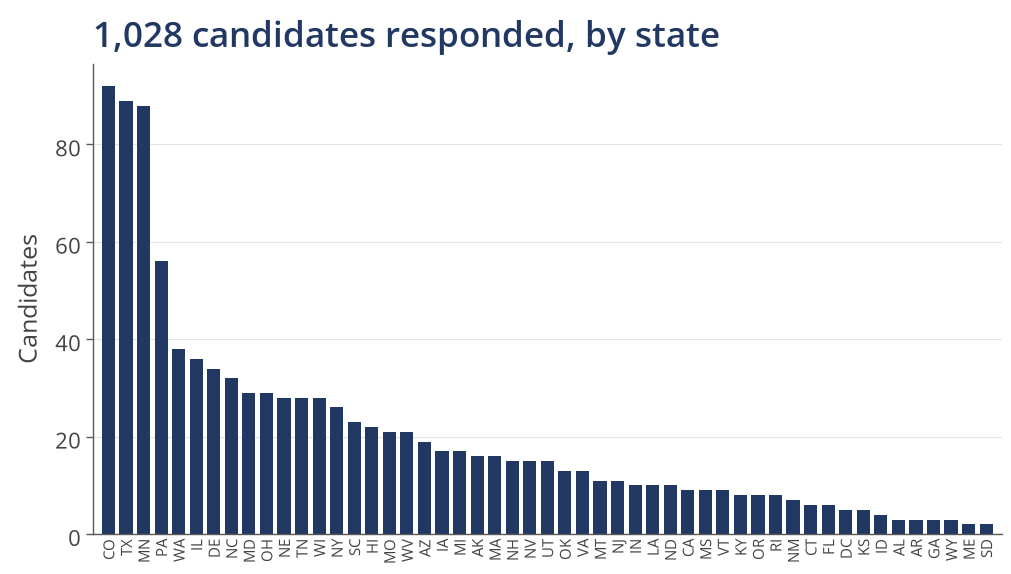

In [5]:
# re-index over every state in the data so a state with no responses still shows up
state_counts = (
    candidates["state"]
    .value_counts()
    .reindex(df["state"].unique(), fill_value=0)
    .sort_values(ascending=False, kind="stable")
)

fig, ax = plt.subplots()
ax.bar(state_counts.index.str.upper(), state_counts.values, width=0.75)
ax.set_title(f"{len(candidates):,} candidates responded, by state")
ax.set_ylabel("Candidates")
ax.tick_params(axis="x", labelrotation=90, labelsize=11, length=0)
ax.margins(x=0.01)
plt.show()

## Responding candidates by party

Most party labels apply to only a handful of candidates, so everything beyond the largest parties is folded into "Other".

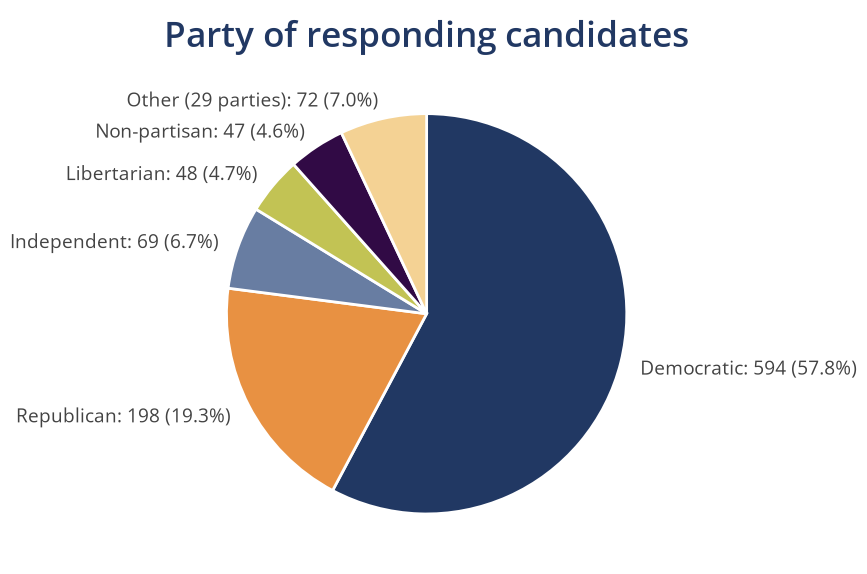

In [6]:
TOP_PARTIES = 5

party_counts = candidates["party"].value_counts()
other_parties = party_counts.iloc[TOP_PARTIES:]
pie_counts = party_counts.iloc[:TOP_PARTIES].copy()
pie_counts[f"Other ({len(other_parties)} parties)"] = other_parties.sum()

labels = [
    f"{party}: {count} ({count / pie_counts.sum():.1%})"
    for party, count in pie_counts.items()
]

fig, ax = plt.subplots()
ax.pie(
    pie_counts,
    labels=labels,
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 14},
)
ax.set_title("Party of responding candidates", loc="center")
plt.show()